In [1]:
import rasterio, numpy as np, geopandas as gpd
from rasterio.windows import Window, bounds
from shapely.geometry import box
from skimage.feature import graycomatrix, graycoprops
from tqdm import tqdm
from skgstat import Variogram

In [2]:
FRAME = 500
with rasterio.open('../LargeImages/HALFRES-KD02-1-20241203-7_IXM150_mos.tif') as ds:
    rows, cols = ds.height // FRAME, ds.width // FRAME
    # valid-pixel mask, decimated 10x for speed (1 value per 10x10 px)
    mask = ds.dataset_mask(out_shape=(ds.height // 10, ds.width // 10)) > 0
    f = FRAME // 10
    valid = mask[:rows*f, :cols*f].reshape(rows, f, cols, f).mean(axis=(1, 3))

    recs = []
    for r in range(rows):
        for c in range(cols):
            win = Window(c*FRAME, r*FRAME, FRAME, FRAME)
            recs.append(dict(frame_id=f"PW_{r:03d}_{c:03d}", row=r, col=c,
                             valid_frac=valid[r, c],
                             geometry=box(*bounds(win, ds.transform))))
    grid = gpd.GeoDataFrame(recs, crs=ds.crs)

In [3]:
grid = grid[grid.valid_frac > 0]
grid.to_file("../Grids/halfres_frames.gpkg", layer="KD02_frames")

In [3]:
FRAME = 500
with rasterio.open('../LargeImages/HALFRES-KD06-1-20241203-7_IXM150_mos.tif') as ds:
    rows, cols = ds.height // FRAME, ds.width // FRAME
    # valid-pixel mask, decimated 10x for speed (1 value per 10x10 px)
    mask = ds.dataset_mask(out_shape=(ds.height // 10, ds.width // 10)) > 0
    f = FRAME // 10
    valid = mask[:rows*f, :cols*f].reshape(rows, f, cols, f).mean(axis=(1, 3))

    recs = []
    for r in range(rows):
        for c in range(cols):
            win = Window(c*FRAME, r*FRAME, FRAME, FRAME)
            recs.append(dict(frame_id=f"PW_{r:03d}_{c:03d}", row=r, col=c,
                             valid_frac=valid[r, c],
                             geometry=box(*bounds(win, ds.transform))))
    grid = gpd.GeoDataFrame(recs, crs=ds.crs)

In [4]:
grid = grid[grid.valid_frac > 0]
grid.to_file("../Grids/halfres_frames.gpkg", layer="KD06_frames")

FRAMES SAVED, RUN BELOW CODE FOR ANALYSIS

In [22]:
HALF_RES = "../LargeImages/HALFRES-KD06-1-20241203-7_IXM150_mos.tif"
GRID     = "../Grids/halfres_frames.gpkg"
LAYER    = "KD06_frames"

FRAME, LEVELS = 500, 32
ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]

def frame_stats(ds, row, col):
    rgb = ds.read(window=Window(col*FRAME, row*FRAME, FRAME, FRAME)).astype(np.float32)
    valid = rgb.sum(axis=0) > 0                      # no-data = 0 in all bands
    if valid.mean() < 0.9:                           # too much black for reliable stats
        return np.nan, np.nan, np.nan
    r, g, b = rgb
    grey = (r + g + b) / 3
    brightness = grey[valid].mean()

    s = r + g + b
    exg = ((2*g - r - b)[valid] / s[valid]).mean()   # normalised Excess Green

    q = (grey / 256 * LEVELS).astype(np.uint8)       # 0–255 → 32 grey levels
    glcm = graycomatrix(q, distances=[1], angles=ANGLES,
                        levels=LEVELS, symmetric=True, normed=True)
    contrast = graycoprops(glcm, "contrast").mean()  # average over 4 directions
    return brightness, exg, contrast

grid = gpd.read_file(GRID, layer=LAYER)

with rasterio.open(HALF_RES) as ds:
    stats = [frame_stats(ds, r, c)
             for r, c in tqdm(zip(grid.row, grid.col), total=len(grid))]

100%|██████████| 4096/4096 [00:25<00:00, 161.77it/s]


In [23]:
grid[["brightness", "exg", "glcm_contrast"]] = stats
grid.to_file(GRID, layer=LAYER)                       # overwrites the layer with the new columns
print(grid[["brightness", "exg", "glcm_contrast"]].describe())

        brightness          exg  glcm_contrast
count  3719.000000  3719.000000    3719.000000
mean    104.675676    -0.021926       1.873123
std      15.163027     0.032253       0.704985
min      63.395031    -0.086218       0.606065
25%      96.479992    -0.042270       1.341809
50%     104.854561    -0.028397       1.824973
75%     114.408009    -0.012090       2.318850
max     168.951706     0.162135       5.814256


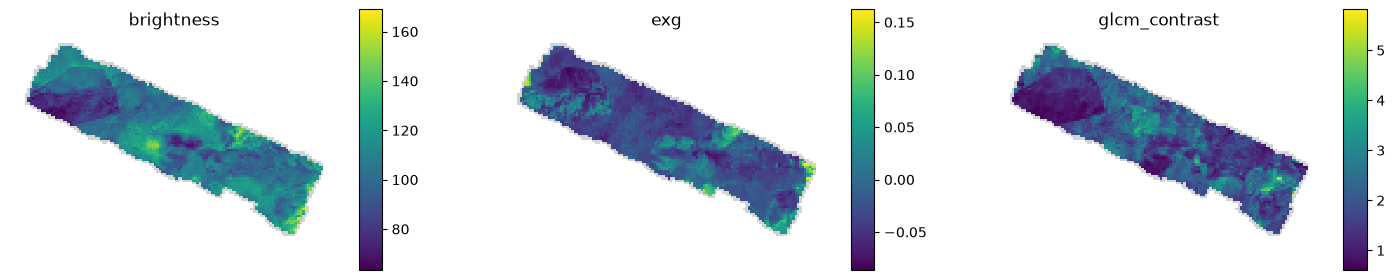

In [24]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, ["brightness", "exg", "glcm_contrast"]):
    grid.plot(column=col, ax=ax, legend=True, cmap="viridis", missing_kwds={"color": "lightgrey"})
    ax.set_title(col); ax.set_axis_off()
plt.show()

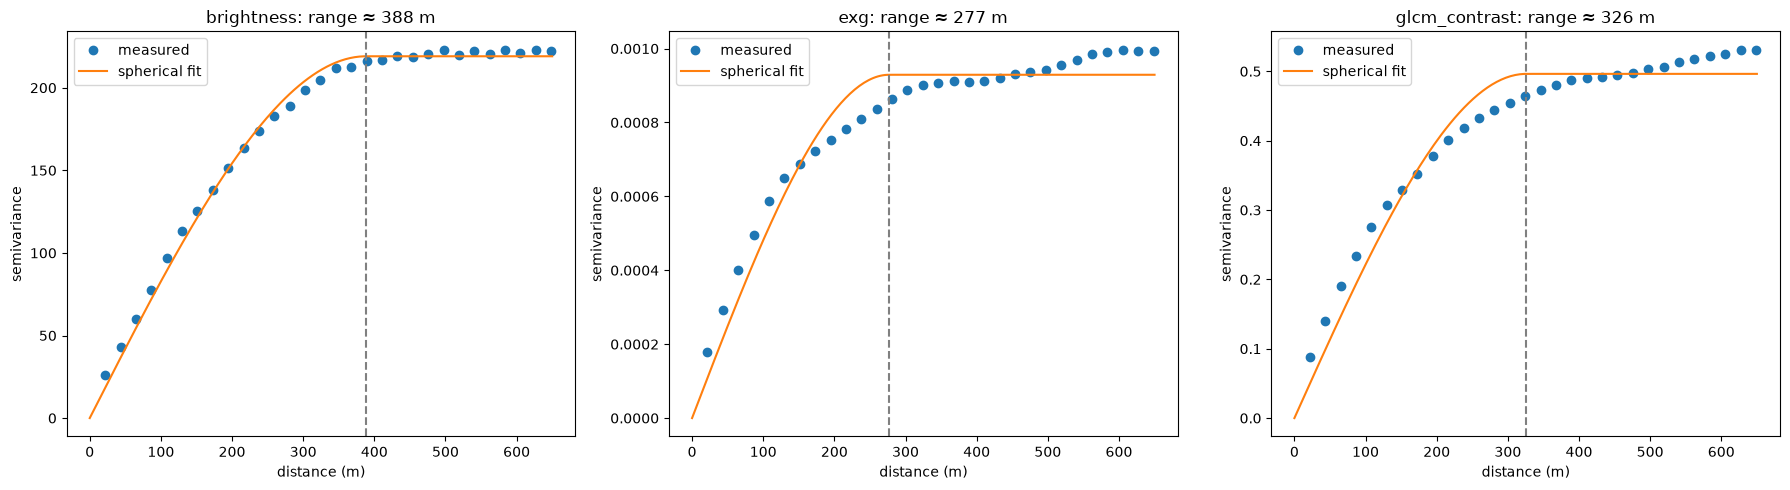

{'brightness': np.float64(388.3897645898403), 'exg': np.float64(276.99838836914773), 'glcm_contrast': np.float64(325.81961687773736)}
max range 388 m, median 326 m
block = 56 frames (1176 m), buffer = 19 frame(s)


In [28]:
GRID, LAYER = "../Grids/halfres_frames.gpkg", "KD06_frames"
FEATURES = ["brightness", "exg", "glcm_contrast"]
FRAME_M  = 21          # frame width in metres
MAXLAG   = 650        # about half the forest's width
N_LAGS   = 30          # ~21 m distance bands, one frame each

grid = gpd.read_file(GRID, layer=LAYER).dropna(subset=FEATURES)
coords = np.column_stack([grid.geometry.centroid.x, grid.geometry.centroid.y])

ranges = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, f in zip(axes, FEATURES):
    V = Variogram(coords, grid[f].values, model="spherical",
                  maxlag=MAXLAG, n_lags=N_LAGS)
    rng, sill, nugget = V.parameters[:3]
    ranges[f] = rng
    ax.plot(V.bins, V.experimental, "o", label="measured")
    x = np.linspace(0, MAXLAG, 200)
    ax.plot(x, V.fitted_model(x), "-", label="spherical fit")
    ax.axvline(rng, ls="--", c="grey")
    ax.set(title=f"{f}: range ≈ {rng:.0f} m", xlabel="distance (m)", ylabel="semivariance")
    ax.legend()
plt.tight_layout(); plt.show()

r = max(ranges.values())                       # cautious: largest range
block_frames  = int(np.ceil(3 * r / FRAME_M))  # ~3× range (Roberts "substantially bigger")
buffer_frames = int(np.ceil(r / FRAME_M))      # buffer ≈ one range
print(ranges)
print(f"max range {r:.0f} m, median {np.median(list(ranges.values())):.0f} m")
print(f"block = {block_frames} frames ({block_frames*FRAME_M} m), buffer = {buffer_frames} frame(s)")

In [18]:
print(np.round(V.experimental[:5] / sill, 2))   # share of the plateau at the first 5 distance bands

[0.29 0.5  0.67 0.8  0.89]


DONE WITH AUTOCORRELATION ESTIMATES, about 300 meters seems accurate, or 16 frames at 21 meters a frame to be 336 meters, using a buffer of 3 frames looses us 33% of the data, but should still leave us with about 2400 tiles at minimum

In [56]:
import numpy as np, geopandas as gpd

GRID, LAYER = "../Grids/halfres_frames.gpkg", "KD02_frames"
BLOCK, BUFFER, MIN_FRAMES = 16, 3, 36

grid = gpd.read_file(GRID, layer=LAYER)
grid = grid.drop(columns=["buffer", "is_buffer", "block_id", "edge_excluded"], errors="ignore")
ok = grid["brightness"].notna().values

# block position, and position inside the block
br, bc = (grid["row"] // BLOCK).values, (grid["col"] // BLOCK).values
ir, ic = (grid["row"] % BLOCK).values, (grid["col"] % BLOCK).values
bottom, right, left = ir >= BLOCK - BUFFER, ic >= BLOCK - BUFFER, ic < BUFFER

def buffer_for(present):
    """last BUFFER rows/cols are buffer where a neighbouring block exists below / right (and corners)"""
    has = lambda dr, dc: np.array([(a + dr, b + dc) in present for a, b in zip(br, bc)])
    return ((right & has(0, 1)) | (bottom & has(1, 0)) |
            (bottom & right & has(1, 1)) | (bottom & left & has(1, -1)))

# provisional buffer with all blocks -> count usable frames -> keep blocks with enough
buf = buffer_for(set(zip(br[ok], bc[ok])))
counts = grid[ok & ~buf].groupby([br[ok & ~buf], bc[ok & ~buf]]).size()
keep = set(counts[counts >= MIN_FRAMES].index)
in_cv = ok & np.array([(a, b) in keep for a, b in zip(br, bc)])

# final buffer using only the kept blocks
grid["block_id"]      = np.where(in_cv, br * 1000 + bc, None)
grid["is_buffer"]     = buffer_for(keep) & in_cv
grid["edge_excluded"] = ok & ~in_cv

use = grid[in_cv & ~grid["is_buffer"]]
print("blocks:", len(keep), "| usable frames:", len(use), "| excluded frames:", int(grid["edge_excluded"].sum()))
print(use.groupby("block_id").size().sort_values().to_string())
grid.to_file(GRID, layer=LAYER)

blocks: 19 | usable frames: 2688 | excluded frames: 225
block_id
4001     45
2005     51
3004     78
4        82
3       106
4003    141
2000    142
1001    158
1004    163
2004    165
3001    167
2001    169
2002    169
2003    169
1002    169
1003    169
3003    169
3002    169
4002    207


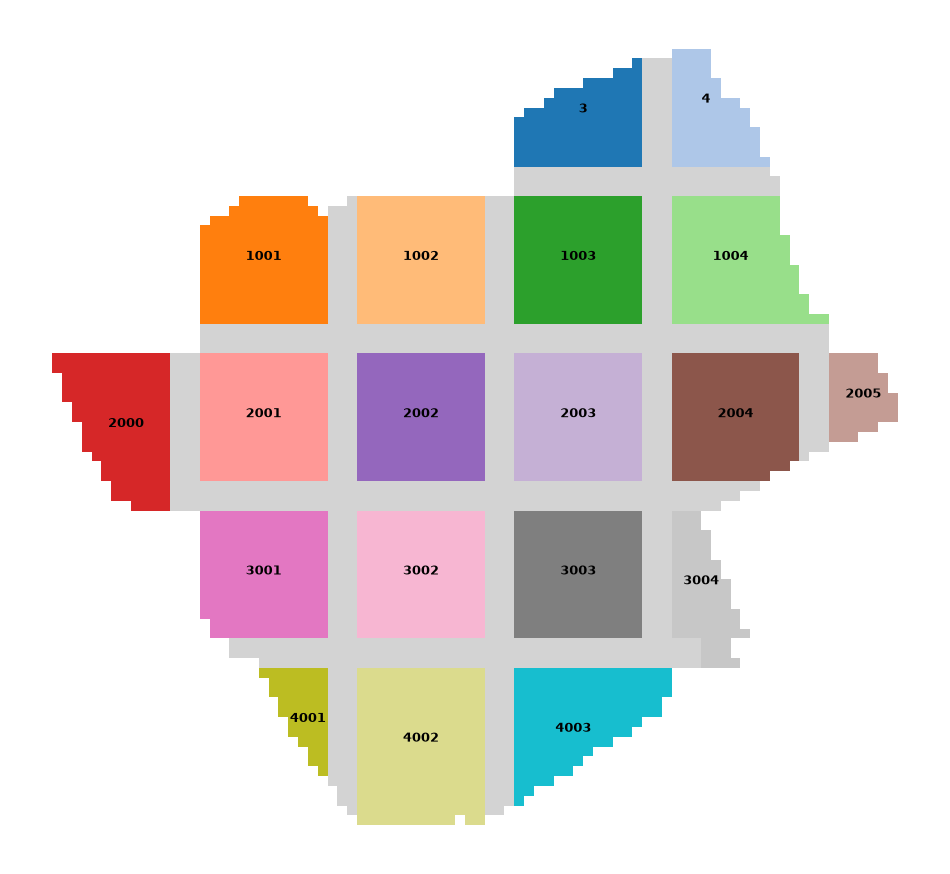

In [51]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 12))
grid[grid["is_buffer"]].plot(ax=ax, color="lightgrey")
nb = grid[grid["block_id"].notna() & ~grid["is_buffer"]]
nb.plot(ax=ax, column="block_id", categorical=True, cmap="tab20")
for bid, g in nb.dissolve("block_id").iterrows():
    p = g.geometry.representative_point()
    ax.annotate(str(bid), (p.x, p.y), ha="center", fontsize=9, weight="bold")
ax.set_axis_off(); plt.show()